In [23]:
import os, random, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam # optimizer
from tensorflow.keras.callbacks import Callback
from PIL import Image

# Fix every source of randomness so results can be reproduced
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [24]:
from collections import Counter

DATA_DIR = "split"            
SPLITS = {"train": "train", "val": "validation", "test": "test"}
IMG_EXT = (".pgm")

for split, folder in SPLITS.items():
    sizes, modes, skipped = Counter(), Counter(), []
    for root, _, files in os.walk(os.path.join(DATA_DIR, folder)):
        for f in files:
            if not f.lower().endswith(IMG_EXT):
                skipped.append(f)                  
                continue
            with Image.open(os.path.join(root, f)) as img:
                sizes[img.size] += 1               # PIL size is (width, height)
                modes[img.mode] += 1               # 'L' = grayscale, 'RGB' = colour

    print(f"------------- {split} ({sum(sizes.values())} images) -------------")
    for (w, h), n in sizes.most_common():
        print(f"  {w} x {h} (W x H): {n} images")
    print(f"  colour modes: {dict(modes)}")
    if skipped:
        print(f"  skipped {len(skipped)} non-image files, e.g. {skipped[:3]}")

------------- train (436 images) -------------
  64 x 60 (W x H): 436 images
  colour modes: {'L': 436}
------------- val (93 images) -------------
  64 x 60 (W x H): 93 images
  colour modes: {'L': 93}
------------- test (95 images) -------------
  64 x 60 (W x H): 95 images
  colour modes: {'L': 95}


In [25]:
# ---- Settings ----
IMG_H, IMG_W = 60, 64              # height, width of every image
CLASSES = ["left", "right", "straight", "up"]
NUM_CLASSES = len(CLASSES)

def load_split(folder):
    #Load every image in a folder.

    X, y = [], []
    for root, _, files in os.walk(folder):
        for f in sorted(files):
            if not f.lower().endswith(IMG_EXT):
                continue                                      # skips .bad and other files
            img = np.asarray(Image.open(os.path.join(root, f)).convert("L"), dtype=np.float32)
            if img.shape != (IMG_H, IMG_W):                   # numpy shape is (height, width)
                raise ValueError(f"{f} has shape {img.shape}, expected {(IMG_H, IMG_W)}")
            X.append(img / 255.0)                             # scale pixels to [0, 1]
            y.append(CLASSES.index(os.path.splitext(f)[0].split("_")[1]))
    return np.stack(X)[..., None], np.array(y)               

X_train, y_train = load_split(os.path.join(DATA_DIR, SPLITS["train"]))
X_val,   y_val   = load_split(os.path.join(DATA_DIR, SPLITS["val"]))
X_test,  y_test  = load_split(os.path.join(DATA_DIR, SPLITS["test"]))

print(f"Train: {X_train.shape}  Val: {X_val.shape}  Test: {X_test.shape}")

Train: (436, 60, 64, 1)  Val: (93, 60, 64, 1)  Test: (95, 60, 64, 1)


split  total             left            right         straight               up
train    436     105 ( 24.1%)     113 ( 25.9%)     109 ( 25.0%)     109 ( 25.0%)
val       93      25 ( 26.9%)      23 ( 24.7%)      26 ( 28.0%)      19 ( 20.4%)
test      95      27 ( 28.4%)      19 ( 20.0%)      21 ( 22.1%)      28 ( 29.5%)


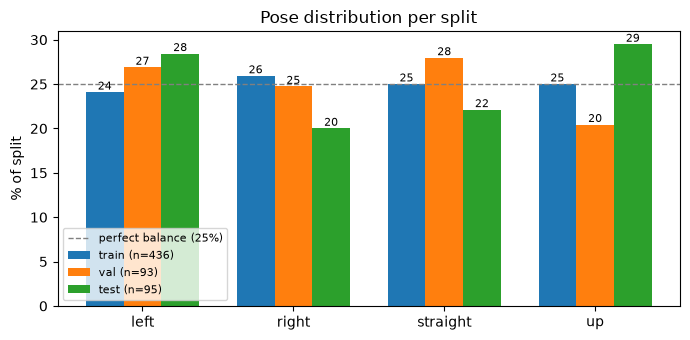

In [26]:
splits = {"train": y_train, "val": y_val, "test": y_test}

# Table of counts and percentages per pose
print(f"{'split':6s} {'total':>5s}  " + "  ".join(f"{c:>15s}" for c in CLASSES))
for name, y in splits.items():
    counts = np.bincount(y, minlength=NUM_CLASSES)
    pct = 100 * counts / counts.sum()
    cells = "  ".join(f"{n:4d} ({p:5.1f}%)".rjust(15) for n, p in zip(counts, pct))
    print(f"{name:6s} {len(y):5d}  {cells}")

# Grouped bar chart of the percentages
x = np.arange(NUM_CLASSES)
width = 0.25
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, (name, y) in enumerate(splits.items()):
    pct = 100 * np.bincount(y, minlength=NUM_CLASSES) / len(y)
    bars = ax.bar(x + (k - 1) * width, pct, width, label=f"{name} (n={len(y)})")
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
ax.axhline(25, color="gray", linestyle="--", linewidth=1, label="perfect balance (25%)")
ax.set_xticks(x)
ax.set_xticklabels(CLASSES)
ax.set_ylabel("% of split")
ax.set_title("Pose distribution per split")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
# EpochTimer callback to record how long each epoch takes
class EpochTimer(Callback):
    # Records how long each epoch takes.
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.perf_counter() - self.start)

In [36]:
# building model A

def build_model_A():
    keras.utils.set_random_seed(SEED)   # same initial weights on every call
    return models.Sequential([
        layers.Input(shape=(60, 64, 1)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dense(4, activation="softmax"),
    ], name="Model_A")

def train(optimizer, epochs, batch_size=32, verbose=0):
    model = build_model_A()
    model.compile(optimizer=optimizer,
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    timer = EpochTimer()
    history = model.fit(X_train, y_train,
                        validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size,
                        callbacks=[timer], verbose=verbose)
    return model, history, timer

In [ ]:
model_A, hist, timer = train(Adam(1e-3), epochs=30, verbose=0)

model_A, history_A, timer_A = train(Adam(1e-3), epochs=30)
time_per_epoch_A = np.mean(timer_A.times[1:])   # skip epoch 1 (one-off setup)
print(f"Average time per epoch: {time_per_epoch_A:.3f} s")
model_A.summary()

Epoch 1/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.2317 - loss: 1.3895 - val_accuracy: 0.2796 - val_loss: 1.3857
Epoch 2/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2477 - loss: 1.3865 - val_accuracy: 0.2473 - val_loss: 1.3861
Epoch 3/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2592 - loss: 1.3862 - val_accuracy: 0.2473 - val_loss: 1.3861
Epoch 4/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2592 - loss: 1.3860 - val_accuracy: 0.2473 - val_loss: 1.3861
Epoch 5/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2592 - loss: 1.3858 - val_accuracy: 0.2473 - val_loss: 1.3861
Epoch 6/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.2592 - loss: 1.3854 - val_accuracy: 0.2473 - val_loss: 1.3855
Epoch 7/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2592 - loss: 1.3847 - val_accuracy: 0.2473 - val_loss: 1.3844
Epoch 8/30
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2592 - loss: 1.3833 - val_accuracy: 0.2473 - v

Model: "Model_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_18 (Conv2D)              │ (None, 60, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 30, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 15, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 303,566 (1.16 MB)

 Trainable params: 101,188 (395.27 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 202,378 (790.54 KB)

In [30]:
# parameter calculation

trainable     = sum(int(np.prod(w.shape)) for w in model_A.trainable_weights)
non_trainable = sum(int(np.prod(w.shape)) for w in model_A.non_trainable_weights)
total = trainable + non_trainable

print(f"Trainable params:     {trainable:,}")
print(f"Non-trainable params: {non_trainable:,}")
print(f"Total params:         {total:,}")
print(f"Approx. size: {total * 4 / 1024:.1f} KB as float32, {total / 1024:.1f} KB as int8")

Trainable params:     101,188
Non-trainable params: 0
Total params:         101,188
Approx. size: 395.3 KB as float32, 98.8 KB as int8


In [31]:
def count_macs(model):
    # Multiply-accumulates of Conv2D and Dense layers.
    total = 0
    for layer in model.layers:
        if isinstance(layer, layers.Conv2D):
            _, h, w, c_out = layer.output.shape          # output height, width, channels
            kh, kw = layer.kernel_size
            c_in = layer.input.shape[-1]
            macs = h * w * kh * kw * c_in * c_out        # one k*k*C_in dot product per output value
        elif isinstance(layer, layers.Dense):
            macs = layer.input.shape[-1] * layer.units
        else:
            continue
        total += macs
        print(f"{layer.name:8s} {macs:>12,}")
    print(f"{'TOTAL':8s} {total:>12,}  (~{total / 1e6:.2f} M MACs per image)")
    return total

macs_a = count_macs(model_A)

conv2d_12    1,105,920
conv2d_13   17,694,720
conv2d_14   17,694,720
dense_8         8,192
dense_9           256
TOTAL      36,503,808  (~36.50 M MACs per image)


In [33]:
model_A.save("model_A.keras", include_optimizer=False)
size_kb_A = os.path.getsize("model_A.keras") / 1024
print(f"Model A size on disk: {size_kb_A:.1f} KB")

Model A size on disk: 1227.8 KB


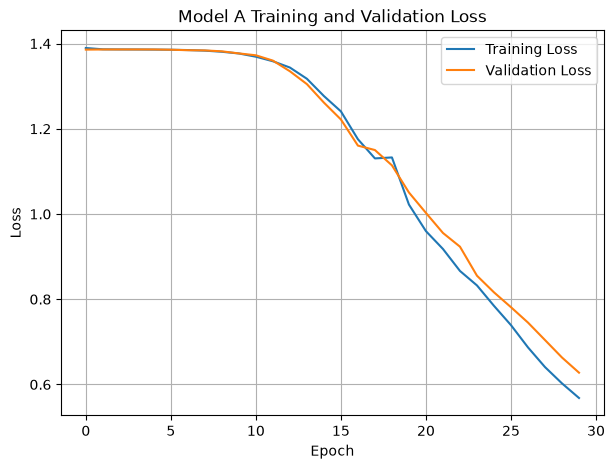

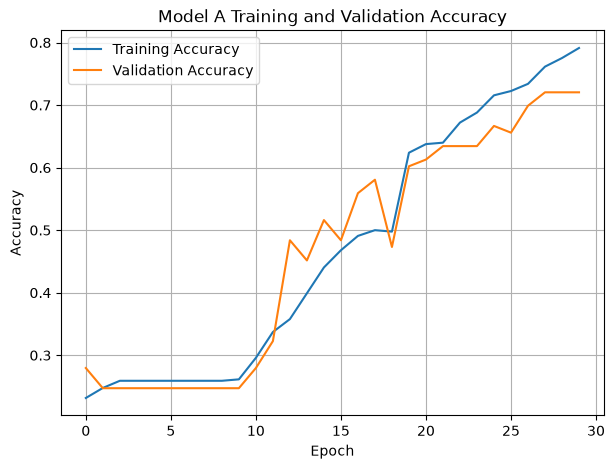

In [34]:
# plot model A training and validation loss and accuracy

plt.figure(figsize=(7,5))
plt.plot(history_A.history["loss"], label="Training Loss")
plt.plot(history_A.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model A Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(history_A.history["accuracy"], label="Training Accuracy")
plt.plot(history_A.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model A Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7158 - loss: 0.6251
Test Accuracy: 71.58%
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


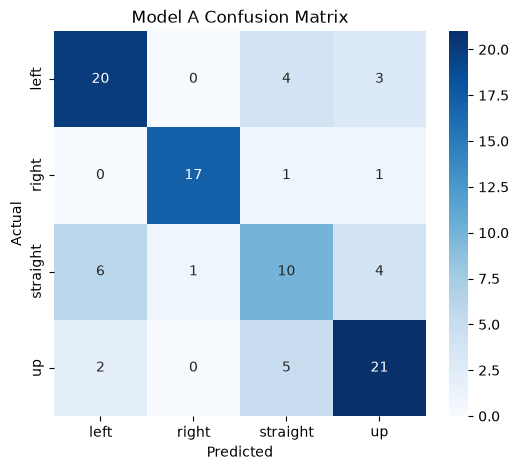

              precision    recall  f1-score   support

        left     0.7143    0.7407    0.7273        27
       right     0.9444    0.8947    0.9189        19
    straight     0.5000    0.4762    0.4878        21
          up     0.7241    0.7500    0.7368        28

    accuracy                         0.7158        95
   macro avg     0.7207    0.7154    0.7177        95
weighted avg     0.7159    0.7158    0.7155        95



In [12]:
# plot confusion matrix and classification report for model A

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_loss, test_accuracy = model_A.evaluate(X_test, y_test, verbose=1)
print(f"Test Accuracy: {test_accuracy*100:.2f}%")

y_pred = np.argmax(model_A.predict(X_test), axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model A Confusion Matrix")
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))